In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Every figure is also saved to figures/ so it can be reused in the report and slides
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# Load the results saved by the previous notebooks
DATA_DIR = Path("data")
rfm_df = pd.read_pickle(DATA_DIR / "rfm_df.pkl")
rfm_scaled = pd.read_pickle(DATA_DIR / "rfm_scaled.pkl")
cleaned_df = pd.read_pickle(DATA_DIR / "cleaned_df.pkl")

## Interpret customer segments

We name each K-means cluster from its median RFM profile. K-means is used for the final segments because it had the higher silhouette score and more balanced cluster sizes than agglomerative clustering.

In [2]:
# Segment names based on the K-means median RFM profiles
segment_names = {
    0: "Recent low spenders",
    1: "Loyal high-value",
    2: "Mid-value at risk",
    3: "Inactive one-time",
}
rfm_df["Segment"] = rfm_df["KMeansCluster"].map(segment_names)

segment_summary = rfm_df.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Revenue=("Monetary", "sum"),
)
segment_summary["CustomerPct"] = segment_summary["Customers"] / segment_summary["Customers"].sum() * 100
segment_summary["RevenuePct"] = segment_summary["Revenue"] / segment_summary["Revenue"].sum() * 100
segment_summary = segment_summary.drop(columns="Revenue").sort_values("Monetary", ascending=False)
segment_summary.round(1)

,Customers,Recency,Frequency,Monetary,CustomerPct,RevenuePct
Segment,,,,,,
Loyal high-value,716,8.0,10.0,3733.9,16.5,64.9
Mid-value at risk,1173,56.0,4.0,1345.6,27.0,23.7
Recent low spenders,837,17.0,2.0,471.7,19.3,5.2
Inactive one-time,1612,177.0,1.0,298.3,37.2,6.2


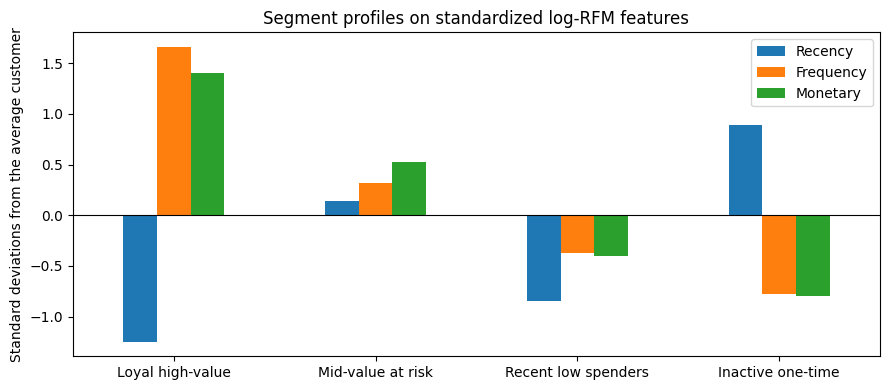

In [3]:
# Average standardized log-RFM value of each segment (0 = the average customer)
segment_order = ["Loyal high-value", "Mid-value at risk", "Recent low spenders", "Inactive one-time"]
segment_profile = rfm_scaled.groupby(rfm_df["Segment"]).mean().loc[segment_order]

ax = segment_profile.plot.bar(figsize=(9, 4), rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Segment profiles on standardized log-RFM features",
    xlabel="",
    ylabel="Standard deviations from the average customer",
)
plt.tight_layout()
save_fig("segment_profiles")
plt.show()

### Segment profiles

- **Loyal high-value (16.5% of customers, 64.9% of revenue):** bought within the last ~8 days, about 10 orders, median spend around 3,700. The most valuable group by far.
- **Mid-value at risk (27.0%, 23.7% of revenue):** regular buyers (about 4 orders, ~1,350 spend) who have not purchased in roughly two months. Worth re-engaging before they lapse.
- **Recent low spenders (19.3%, 5.2% of revenue):** purchased recently but only once or twice with small baskets. Mostly newer customers who could grow into repeat buyers.
- **Inactive one-time (37.2%, 6.2% of revenue):** a single small order about six months ago. The largest group but contributes little revenue.

In the chart above, low Recency is good and high Frequency and Monetary are good.

Agglomerative clustering agrees with these segments at the top and bottom but splits the middle differently (see the comparison above), so customers near a boundary could reasonably belong to either neighbouring segment.

## Develop marketing recommendations

We turn the four K-means segments into marketing actions. Before writing recommendations, we look at a few extra behaviours for each segment that the RFM medians do not show directly:

- **Order habits:** typical order value, items per order, and the usual number of days between a customer's orders
- **Timing:** how recently each segment bought, and how much of its spending came in the September to November holiday ramp
- **Products:** the items bought by the most customers in each segment, to use in targeted offers

In [4]:
# Attach each customer's segment to the cleaned transactions
segment_tx = cleaned_df.merge(rfm_df[["CustomerID", "Segment"]], on="CustomerID")

# One row per purchase invoice
invoices = segment_tx.groupby(["Segment", "CustomerID", "InvoiceNo"]).agg(
    OrderValue=("TotalPrice", "sum"),
    Items=("StockCode", "nunique"),
    InvoiceDate=("InvoiceDate", "min"),
).reset_index().sort_values("InvoiceDate")

# Days between consecutive orders from the same customer (repeat buyers only)
invoices["DaysSincePrevOrder"] = invoices.groupby("CustomerID")["InvoiceDate"].diff().dt.days

# Customer home country and share of each customer's spending in Sep-Nov
customer_country = segment_tx.groupby("CustomerID")["Country"].first()
holiday_spend = segment_tx[segment_tx["InvoiceDate"].dt.month.isin([9, 10, 11])].groupby("Segment")["TotalPrice"].sum()

segment_behaviour = pd.DataFrame({
    "Customers": rfm_df.groupby("Segment")["CustomerID"].count(),
    "RevenuePct": rfm_df.groupby("Segment")["Monetary"].sum() / rfm_df["Monetary"].sum() * 100,
    "MedianOrderValue": invoices.groupby("Segment")["OrderValue"].median(),
    "MedianItemsPerOrder": invoices.groupby("Segment")["Items"].median(),
    "MedianDaysBetweenOrders": invoices.groupby("Segment")["DaysSincePrevOrder"].median(),
    "OneOrderPct": rfm_df.groupby("Segment")["Frequency"].apply(lambda f: (f == 1).mean() * 100),
    "UKPct": rfm_df.assign(UK=rfm_df["CustomerID"].map(customer_country).eq("United Kingdom")).groupby("Segment")["UK"].mean() * 100,
    "SepNovSpendPct": holiday_spend / segment_tx.groupby("Segment")["TotalPrice"].sum() * 100,
}).sort_values("RevenuePct", ascending=False)

segment_behaviour.round(1)

,Customers,RevenuePct,MedianOrderValue,MedianItemsPerOrder,MedianDaysBetweenOrders,OneOrderPct,UKPct,SepNovSpendPct
Segment,,,,,,,,
Loyal high-value,716,64.9,321.5,15.0,14.0,0.0,88.7,34.8
Mid-value at risk,1173,23.7,308.1,16.0,48.0,2.8,88.4,33.6
Inactive one-time,1612,6.2,203.9,12.0,61.0,73.9,91.6,26.4
Recent low spenders,837,5.2,208.3,15.0,55.0,32.0,92.1,61.7


In [5]:
# How long since each segment's customers last bought (row percentages)
recency_bins = pd.cut(
    rfm_df["Recency"],
    bins=[0, 30, 60, 90, 180, 400],
    labels=["0-30 days", "31-60", "61-90", "91-180", "181+"],
)
recency_mix = pd.crosstab(rfm_df["Segment"], recency_bins, normalize="index") * 100
display(recency_mix.round(1))

# When each segment's customers made their first purchase
first_purchase = segment_tx.groupby("CustomerID")["InvoiceDate"].min().dt.to_period("Q")
first_quarter_mix = pd.crosstab(rfm_df["Segment"], rfm_df["CustomerID"].map(first_purchase).rename("FirstPurchaseQuarter"))
display(first_quarter_mix)

# Mid-value at risk: share of customers who have gone longer than their own usual gap between orders
usual_gap = invoices.groupby("CustomerID")["DaysSincePrevOrder"].median()
at_risk = rfm_df[rfm_df["Segment"] == "Mid-value at risk"].copy()
at_risk["UsualGap"] = at_risk["CustomerID"].map(usual_gap)
overdue_pct = (at_risk["Recency"] > at_risk["UsualGap"]).mean() * 100
print(f"Mid-value at risk customers past their usual reorder gap: {overdue_pct:.1f}%")
print(f"Mid-value at risk revenue: {at_risk['Monetary'].sum():,.0f} GBP")

Recency,0-30 days,31-60,61-90,91-180,181+
Segment,,,,,
Inactive one-time,0.2,11.8,15.8,23.4,48.7
Loyal high-value,92.9,6.1,0.8,0.0,0.1
Mid-value at risk,24.0,31.8,19.8,18.1,6.3
Recent low spenders,83.3,16.7,0.0,0.0,0.0


FirstPurchaseQuarter,2010Q4,2011Q1,2011Q2,2011Q3,2011Q4
Segment,,,,,
Inactive one-time,200,456,377,343,236
Loyal high-value,379,209,69,40,19
Mid-value at risk,235,485,274,139,40
Recent low spenders,71,99,106,134,427


Mid-value at risk customers past their usual reorder gap: 44.7%
Mid-value at risk revenue: 2,114,718 GBP


In [6]:
# Products bought by the most customers in each segment
# Non-product codes (postage, fees, manual adjustments) are excluded
non_product_codes = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "PADS", "CRUK"]
product_tx = segment_tx[~segment_tx["StockCode"].astype(str).isin(non_product_codes)]

top_products = (
    product_tx.groupby(["Segment", "Description"])["CustomerID"].nunique()
    .rename("Customers")
    .reset_index()
    .sort_values(["Segment", "Customers"], ascending=[True, False])
    .groupby("Segment")
    .head(5)
    .reset_index(drop=True)
)
top_products["PctOfSegment"] = top_products["Customers"] / top_products["Segment"].map(segment_behaviour["Customers"]) * 100
top_products.round(1)

,Segment,Description,Customers,PctOfSegment
0,Inactive one-time,WHITE HANGING HEART T-LIGHT HOLDER,198,12.3
1,Inactive one-time,REGENCY CAKESTAND 3 TIER,177,11.0
2,Inactive one-time,PARTY BUNTING,148,9.2
3,Inactive one-time,ASSORTED COLOUR BIRD ORNAMENT,130,8.1
4,Inactive one-time,SET OF 3 CAKE TINS PANTRY DESIGN,127,7.9
5,Loyal high-value,REGENCY CAKESTAND 3 TIER,262,36.6
6,Loyal high-value,WHITE HANGING HEART T-LIGHT HOLDER,253,35.3
7,Loyal high-value,JUMBO BAG RED RETROSPOT,252,35.2
8,Loyal high-value,LUNCH BAG RED RETROSPOT,246,34.4
9,Loyal high-value,PACK OF 72 RETROSPOT CAKE CASES,240,33.5


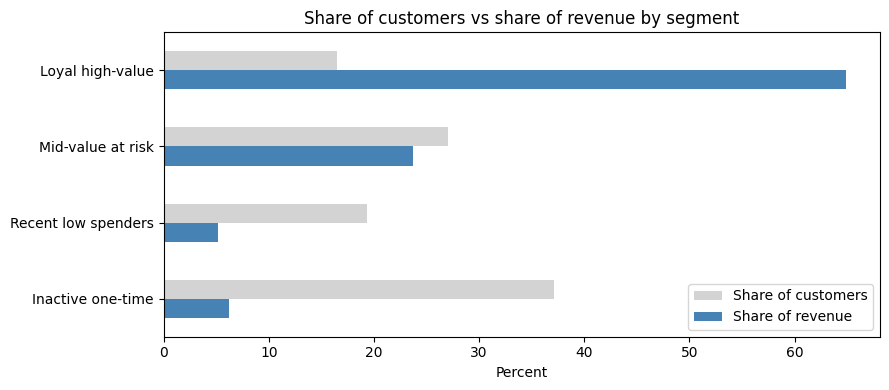

In [7]:
# Revenue share by segment, with each segment's recommended priority
priority_order = ["Loyal high-value", "Mid-value at risk", "Recent low spenders", "Inactive one-time"]
plot_data = segment_behaviour.loc[priority_order, ["Customers", "RevenuePct"]].copy()
plot_data["CustomerPct"] = plot_data["Customers"] / plot_data["Customers"].sum() * 100

ax = plot_data[["CustomerPct", "RevenuePct"]].plot.barh(figsize=(9, 4), color=["lightgray", "steelblue"])
ax.invert_yaxis()
ax.set(title="Share of customers vs share of revenue by segment", xlabel="Percent", ylabel="")
ax.legend(["Share of customers", "Share of revenue"])
plt.tight_layout()
save_fig("segment_revenue_share")
plt.show()

### Recommendations by segment

**1. Loyal high-value (16.5% of customers, 64.9% of revenue): retain and reward**

*Evidence:* these customers reorder about every two weeks, almost all bought in the last 30 days, and they carry nearly two thirds of revenue. Losing even a small number of them costs more than any other segment can add.

- **Loyalty / VIP tier:** early access to new seasonal ranges, priority stock allocation on best sellers, and free delivery above a threshold. Many of these customers buy in wholesale-sized baskets, so service perks are likely to matter more than small discounts.
- **Replenishment reminders:** since the typical gap is about 14 days, send a reorder reminder with their most-bought items when a customer passes roughly twice their usual gap, before they drift into the at-risk group.
- **Cross-sell, not discount:** recommend items frequently bought by other loyal customers (see the product table) instead of discounting items they already buy at full price.
- **Avoid over-contacting:** keep promotional volume low; this group is already buying.
- *KPI:* retention rate and order frequency for this segment; number of customers moving from loyal to at-risk each month.

**2. Mid-value at risk (27.0%, 23.7% of revenue): win back before they lapse**

*Evidence:* these customers normally reorder about every 48 days, but their median recency is 56 days, about 76% have not bought in the last 30 days, and about 45% are already past their own usual reorder gap. This segment holds about 2.1M GBP of revenue, the largest amount that can still realistically be saved.

- **Triggered win-back:** automatically contact a customer once they pass their own usual gap between orders (for example, around 60 days), instead of waiting for a fixed calendar campaign.
- **Time-limited incentive:** a modest discount or free shipping on the next order with a short expiry (for example, 14 days) to create urgency. Use bigger offers only for customers whose past spending justifies them.
- **Personalised content:** feature the products they bought before and close substitutes, since this group buys the same core items as the loyal segment (cake stands, T-light holders, cake cases).
- **Feedback request:** a short survey for customers who do not respond, to learn whether they switched supplier or simply had no need.
- *KPI:* reactivation rate (share who place another order within 30 days of contact) and revenue recovered per GBP of discount given.

**3. Recent low spenders (19.3%, 5.2% of revenue): convert to repeat buyers**

*Evidence:* most of these customers are new. About half (427 of 837) made their first purchase in the last quarter of 2011, about 62% of their spending came in September to November, and their most common products are seasonal items such as Christmas paper chain kits. Their orders are smaller (median order value about 210 GBP vs about 320 GBP for loyal customers) and about a third have ordered only once.

- **Onboarding sequence:** a welcome series after the first order that introduces the wider range, best sellers, and how to reorder.
- **Second-order incentive:** an offer valid on the next order within 30-45 days. The second order is the step that most often separates a one-time buyer from a repeat customer.
- **Grow basket size:** free shipping or a small discount once an order passes a threshold set slightly above their current typical order value, plus product bundles of commonly bought-together items.
- **Post-holiday follow-up:** because much of this group was acquired during the holiday ramp, plan a January to February campaign so they do not become next year's inactive one-time customers.
- *KPI:* second-purchase rate within 60 days, average order value, and share of this segment that moves into the at-risk or loyal segments.

**4. Inactive one-time (37.2%, 6.2% of revenue): low-cost reactivation**

*Evidence:* the largest segment but the smallest revenue per customer. About 74% have placed only one order, and about half have not bought in more than six months.

- **Low-cost channels only:** automated email rather than paid advertising or sales calls, because expected revenue per customer is low.
- **Split by recency:** customers who lapsed within the last ~90 days get a "we miss you" offer; customers inactive for 6+ months get one final reactivation message before being moved to a lower-frequency mailing list.
- **Seasonal hook:** time reactivation emails before the September to November peak featuring the home decor and party items this segment bought most (T-light holders, cake stands, party bunting).
- **List hygiene:** stop sending to contacts who do not engage after the reactivation attempt, which lowers cost and protects email deliverability for the other segments.
- *KPI:* reactivation rate and cost per reactivated customer; unsubscribe and bounce rates.

### Overall priorities

| Priority | Segment | Goal | Main action | Spend level |
|---|---|---|---|---|
| 1 | Loyal high-value | Retain | Loyalty tier, replenishment reminders, cross-sell | Medium (service perks, not discounts) |
| 2 | Mid-value at risk | Win back | Triggered win-back with time-limited incentive | Medium to high |
| 3 | Recent low spenders | Develop | Onboarding and second-order incentive, basket-size thresholds | Medium |
| 4 | Inactive one-time | Reactivate cheaply | Automated email, then reduce contact | Low |

**Cross-segment recommendations**

- **Plan around the seasonal peak:** monthly sales roughly double from summer to November, so loyalty offers, new product launches, and reactivation campaigns should be ready by late August.
- **Focus on the UK first:** about 88-92% of customers in every segment are UK-based, so UK campaigns reach most of each segment. Non-UK customers are few but some (for example the Netherlands and EIRE) spend heavily per customer, so they may suit account-style follow-up.
- **Re-score customers regularly:** recompute RFM features and segment assignments monthly so customers are moved between campaigns as their behaviour changes (for example, a recent low spender who places a third order should leave the second-order campaign).
- **Test before scaling:** run each campaign with a randomly held-out control group so the effect of the campaign can be measured against customers who were not contacted.

### Limitations of these recommendations

- The data has no product cost, margin, or marketing cost information, so the recommended incentive levels are directional and should be checked against margins before use.
- There is no record of past campaigns or customer responses, so expected response rates are unknown until the campaigns are tested.
- The dataset covers about one year and appears to include many wholesale customers, so behaviour may differ from a typical consumer retailer.
- As noted when choosing K, the segments overlap moderately (silhouette about 0.34). Customers near segment boundaries may fit more than one campaign, which is another reason to re-score them regularly.

## Limitations

- About 25% of the raw rows had no CustomerID and were dropped, so those buyers are not in any segment.
- Monetary is gross spending. We removed cancellations but did not subtract them from the original orders.
- We only use three features. RFM says nothing about what customers buy.
- The data covers one year and Recency is measured right after the holiday peak, so customers who first bought in autumn look like recent low spenders partly because they have not had time to reorder.
- The clusters overlap (silhouette 0.34) and the two methods agree only weakly, so the segments are a useful way to split a continuum and not sharply separate groups.
- There are no labels or campaign results to check the segments against.

## Conclusion

After cleaning we had 397,884 purchase rows from 4,338 customers. K-means with K = 4 on log-scaled RFM features gave four segments: loyal high-value customers (16.5% of customers, 64.9% of revenue), mid-value customers at risk of leaving (27.0%, 23.7%), recent low spenders (19.3%, 5.2%), and inactive one-time buyers (37.2%, 6.2%). The result was stable across random seeds. Agglomerative clustering found the same top and bottom groups but split the middle differently, so we treat the middle boundaries as approximate.

With more time we would use net revenue after returns, add features about what customers buy, and try a Gaussian mixture model since it gives probabilities instead of hard cluster labels.

## References

1. Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
2. Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. Journal of Database Marketing & Customer Strategy Management, 19(3), 197-208.
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
4. Virtanen, P., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261-272.